# 04 · Distance and kernel methods: KNN and SVM

Two classic non-linear methods that work best on **small-to-medium, all-numeric, scaled** data.

| | k-Nearest Neighbours | Support Vector Machine |
|---|---|---|
| Idea | predict the average/majority of the $k$ closest training points | find the boundary with the widest margin; kernels make it non-linear |
| Key params | `n_neighbors`, `weights`, distance metric | `C` (less regularisation as C grows), `gamma` (RBF kernel width), `kernel` |
| Strengths | no training, simple, local | strong on small, high-dimensional data (text, genomics) |
| Weaknesses | slow prediction, curse of dimensionality, needs scaling | scales ~$O(n^2)$, no native probabilities, needs scaling |

Both are **distance-based, so feature scaling is not optional.**

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
rng = np.random.default_rng(SEED)

# One consistent, colour-blind-friendly style for every notebook.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
GREY = "#a3a29c"
plt.rcParams.update({
    "figure.figsize": (8, 4.5), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.8,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "lines.linewidth": 2, "font.size": 10, "legend.frameon": False,
})
pd.set_option("display.precision", 4)

## 1. Scaling matters (a lot)
The wine dataset has features in very different units (e.g. proline ~ 1000, hue ~ 1).

In [2]:
from sklearn.datasets import load_wine
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

X, y = load_wine(return_X_y=True, as_frame=True)
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
print(X.describe().loc[["mean", "std"]].T.head(6))
raw = cross_val_score(KNeighborsClassifier(), X, y, cv=cv).mean()
scaled = cross_val_score(make_pipeline(StandardScaler(), KNeighborsClassifier()), X, y, cv=cv).mean()
print(f"\nKNN accuracy unscaled: {raw:.3f}  |  scaled: {scaled:.3f}")

                      mean      std
alcohol            13.0006   0.8118
malic_acid          2.3363   1.1171
ash                 2.3665   0.2743
alcalinity_of_ash  19.4949   3.3396
magnesium          99.7416  14.2825
total_phenols       2.2951   0.6259

KNN accuracy unscaled: 0.680  |  scaled: 0.972


## 2. Choosing k: bias vs variance
Small $k$: wiggly boundary, overfits. Large $k$: smooth, underfits.

Text(0.5, 1.0, 'KNN validation curve')

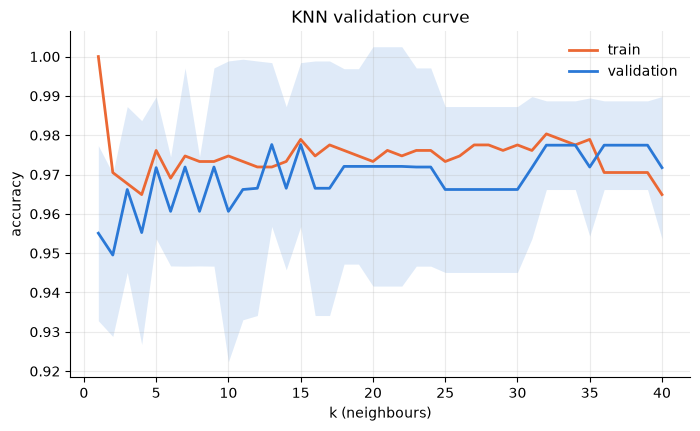

In [3]:
from sklearn.model_selection import validation_curve

ks = np.arange(1, 41)
tr, va = validation_curve(make_pipeline(StandardScaler(), KNeighborsClassifier()), X, y,
                          param_name="kneighborsclassifier__n_neighbors", param_range=ks, cv=cv)
fig, ax = plt.subplots()
ax.plot(ks, tr.mean(1), label="train", color=PALETTE[1])
ax.plot(ks, va.mean(1), label="validation", color=PALETTE[0])
ax.fill_between(ks, va.mean(1) - va.std(1), va.mean(1) + va.std(1), color=PALETTE[0], alpha=0.15, lw=0)
ax.set_xlabel("k (neighbours)"); ax.set_ylabel("accuracy"); ax.legend(); ax.set_title("KNN validation curve")

## 3. SVM decision boundaries

On the two-moons data a linear SVM can't bend; the RBF kernel can. `C` and `gamma` control how tightly it hugs the training points.

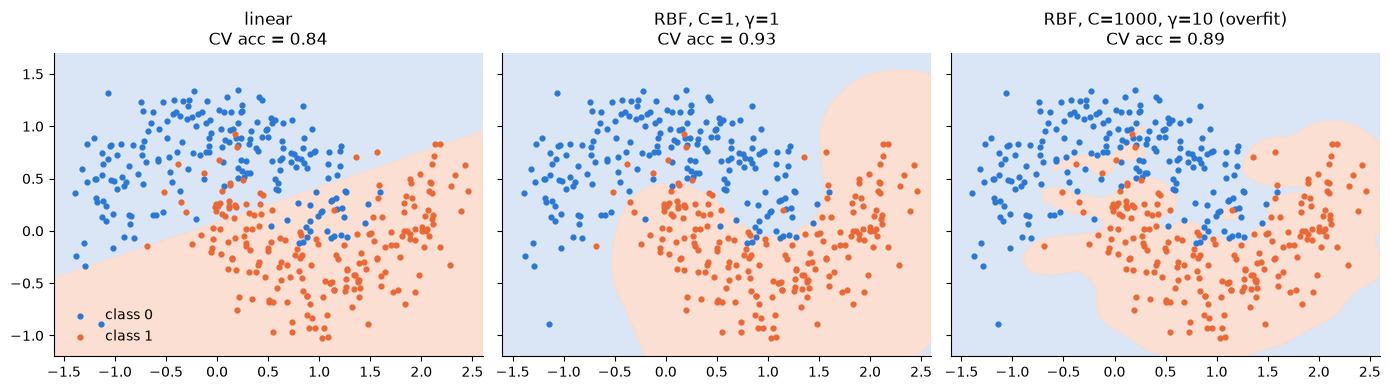

In [4]:
from sklearn.datasets import make_moons
from sklearn.svm import SVC
from matplotlib.colors import ListedColormap

Xm, ym = make_moons(400, noise=0.25, random_state=SEED)
xx, yy = np.meshgrid(np.linspace(-1.6, 2.6, 300), np.linspace(-1.2, 1.7, 300))
grid = np.c_[xx.ravel(), yy.ravel()]
cmap_bg = ListedColormap(["#d6e4f5", "#fbdccd"])

configs = [("linear", dict(kernel="linear", C=1)), ("RBF, C=1, γ=1", dict(kernel="rbf", C=1, gamma=1)),
           ("RBF, C=1000, γ=10 (overfit)", dict(kernel="rbf", C=1000, gamma=10))]
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, (title, kw) in zip(axes, configs):
    m = make_pipeline(StandardScaler(), SVC(**kw)).fit(Xm, ym)
    acc = cross_val_score(make_pipeline(StandardScaler(), SVC(**kw)), Xm, ym, cv=5).mean()
    ax.contourf(xx, yy, m.predict(grid).reshape(xx.shape), cmap=cmap_bg, alpha=0.9)
    ax.scatter(*Xm[ym == 0].T, s=12, color=PALETTE[0], label="class 0")
    ax.scatter(*Xm[ym == 1].T, s=12, color=PALETTE[1], label="class 1")
    ax.set_title(f"{title}\nCV acc = {acc:.2f}"); ax.grid(False)
axes[0].legend(loc="lower left")
plt.tight_layout()

## 4. Tuning C and gamma together
They interact, so search a log-spaced grid.

In [5]:
from sklearn.model_selection import GridSearchCV

search = GridSearchCV(make_pipeline(StandardScaler(), SVC()),
                      {"svc__C": np.logspace(-2, 3, 6), "svc__gamma": np.logspace(-3, 1, 5)}, cv=cv)
search.fit(X, y)
print("best:", search.best_params_, f"CV acc = {search.best_score_:.3f}")
heat = pd.DataFrame(search.cv_results_)[["param_svc__C", "param_svc__gamma", "mean_test_score"]]
heat.pivot(index="param_svc__C", columns="param_svc__gamma", values="mean_test_score").round(3)

best: {'svc__C': np.float64(1.0), 'svc__gamma': np.float64(0.01)} CV acc = 0.989


param_svc__gamma,0.001,0.010,0.100,1.000,10.000
param_svc__C,,,,,
0.01,0.399,0.399,0.399,0.399,0.399
0.10,0.399,0.758,0.967,0.399,0.399
1.00,0.882,0.989,0.978,0.596,0.399
10.00,0.989,0.978,0.983,0.641,0.399
100.00,0.978,0.966,0.983,0.641,0.399
1000.00,0.961,0.966,0.983,0.641,0.399


## 5. The curse of dimensionality (why KNN struggles with many features)

In high dimensions, the nearest and the farthest point end up at almost the same distance, so "nearest" stops meaning much.

In [6]:
dims = [2, 10, 50, 200, 1000]
ratios = []
for d in dims:
    pts = rng.uniform(size=(1000, d))
    dist = np.linalg.norm(pts[1:] - pts[0], axis=1)
    ratios.append(dist.min() / dist.max())
pd.Series(ratios, index=pd.Index(dims, name="dimensions"), name="nearest / farthest distance").round(3)

dimensions
2       0.010
10      0.317
50      0.597
200     0.780
1000    0.895
Name: nearest / farthest distance, dtype: float64

## Takeaways
- Always `StandardScaler` (or similar) in the pipeline.
- KNN: good sanity check and baseline for low-dimensional numeric data; also useful as an ensemble member.
- SVM (RBF): strong on small datasets; tune `C` × `gamma` on a log grid. For >~50k rows use linear models or boosting instead.
- Regression versions: `KNeighborsRegressor`, `SVR`.